In [1]:
import sys
sys.path.insert(0, "../data_prep")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import jump_analysis as ja
from config import DATA_PATH
print("imported ok")

imported ok


In [2]:
wavs = sorted(set(Path(DATA_PATH).glob("train/**/*.WAV")) | set(Path(DATA_PATH).glob("test/**/*.WAV")))
print(DATA_PATH)
print(len(wavs), "WAV files")

/Users/ziyaahmad/Code/mouse_vocalization_2026/data
22516 WAV files


In [3]:
out = Path("jump_review"); out.mkdir(exist_ok=True)
rng = np.random.default_rng(0)
sample = rng.choice(len(wavs), size=5, replace=False)

all_rows = []
for i in sample:
    rows, audit = ja.inspect_file(wavs[i], 10, 2, out)   # threshold kHz, min frames, output folder
    print(wavs[i].name, audit["status"], "active frames:", audit["active_frames"], "jumps:", audit["candidate_jumps"])
    all_rows += rows

pd.DataFrame(all_rows)

DBA_3247_55.WAV included active frames: 87 jumps: 0
DBA_3243_713.WAV included active frames: 39 jumps: 1
DBA_3171_1152.WAV included active frames: 113 jumps: 2
DBA_3171_399.WAV included active frames: 55 jumps: 1
DBA_9858_517.WAV included active frames: 72 jumps: 1


,file,frame,time_ms,pre_khz,post_khz,signed_jump_khz,jump_khz,review_status
0,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,32,17.066667,53.437500,64.570312,11.132812,11.132812,unreviewed
1,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,21,11.200000,67.968750,88.476562,20.507812,20.507812,unreviewed
2,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,39,20.800000,86.132812,64.101562,-22.031250,22.031250,unreviewed
3,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,21,11.200000,85.078125,64.218750,-20.859375,20.859375,unreviewed
4,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,64,34.133333,47.343750,65.273438,17.929688,17.929688,unreviewed


In [4]:
rng = np.random.default_rng(1)
order = rng.permutation(len(wavs))
rows_all, audits = [], []
n_inc = 0
for idx in order:
    if n_inc >= 100:
        break
    p = wavs[int(idx)]
    try:
        rows, audit = ja.inspect_file(p, 10, 2, out)
    except Exception as e:
        audits.append(dict(file=str(p), status="error"))
        continue
    audits.append(audit)
    if audit["status"] == "included":
        n_inc += 1
        rows_all += rows

jumps = pd.DataFrame(rows_all)
print(n_inc, "files,", len(jumps), "jumps,", jumps["file"].nunique(), "files with jumps")

100 files, 81 jumps, 41 files with jumps


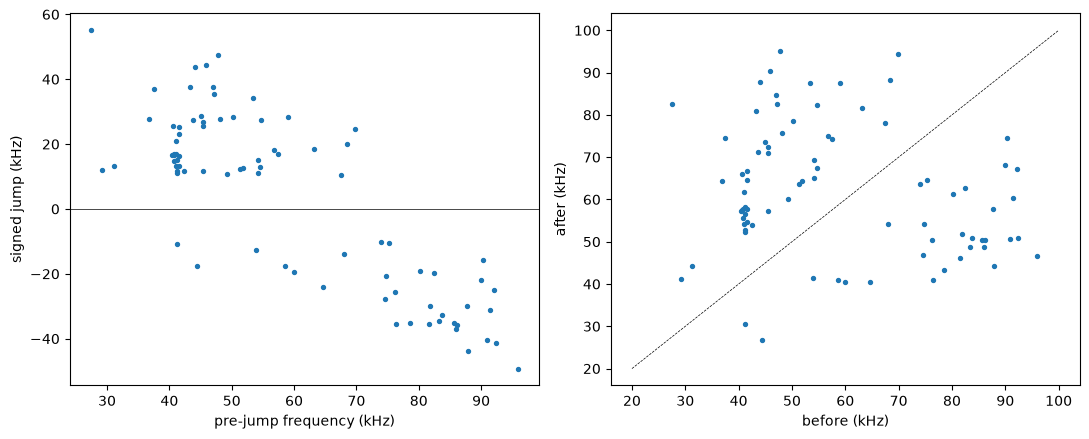

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(jumps["pre_khz"], jumps["signed_jump_khz"], s=8)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set_xlabel("pre-jump frequency (kHz)"); ax[0].set_ylabel("signed jump (kHz)")
ax[1].scatter(jumps["pre_khz"], jumps["post_khz"], s=8)
ax[1].plot([20, 100], [20, 100], "k--", lw=0.5)
ax[1].set_xlabel("before (kHz)"); ax[1].set_ylabel("after (kHz)")
plt.tight_layout(); plt.show()

In [6]:
cl = jumps[jumps["pre_khz"].between(39, 43)]
print(len(cl), "jumps start near 41 kHz")
print(cl["time_ms"].describe())
print(cl["file"].map(lambda p: Path(p).name).value_counts().head(8))

17 jumps start near 41 kHz
count    17.000000
mean     12.737255
std      13.369128
min       4.266667
25%       6.400000
50%       8.000000
75%      11.733333
max      60.800000
Name: time_ms, dtype: float64
file
DBA_3243_291.WAV     2
DBA_3170_841.WAV     1
DBA_3170_283.WAV     1
DBA_3249_446.WAV     1
DBA_3243_53.WAV      1
DBA_3172_1184.WAV    1
DBA_3170_114.WAV     1
DBA_3248_535.WAV     1
Name: count, dtype: int64
